In [1]:
import matplotlib.pyplot as plt
import pandas as pd

Load datasets:

In [2]:
dataset1 = pd.read_csv("../raw_data/calisthenics_oahs_keypoints.csv")
dataset2 = pd.read_csv("../raw_data/exercise_recognition_landmarks.csv")
dataset3 = pd.read_csv("../raw_data/imagePoses.csv")
dataset4 = pd.read_csv("../raw_data/yoga82_handstand_keypoints.csv")

d1_exercises = dataset1["skill_id"].dropna()
d2_exercises = dataset2["pose"].dropna()
d3_exercises = dataset3["excercise"].dropna()
d4_exercises = dataset4["exercise"].dropna()

List all exercises in the datasets:

In [3]:
all_exercises = (
    d1_exercises.unique().tolist()
    + d2_exercises.unique().tolist()
    + d3_exercises.unique().tolist()
    + d4_exercises.unique().tolist()
)

print(all_exercises)
print(len(all_exercises))

['none', 'oahs', 'jumping_jacks_down', 'jumping_jacks_up', 'pullups_down', 'pullups_up', 'pushups_down', 'pushups_up', 'situp_down', 'situp_up', 'squats_down', 'squats_up', 'pushup', 'pullup', 'chest dips', 'bent over row', 'shoulder press', 'squat', 'lunges', 'plank', 'glute bridge', 'handstand']
22


List number of entries per exercise:

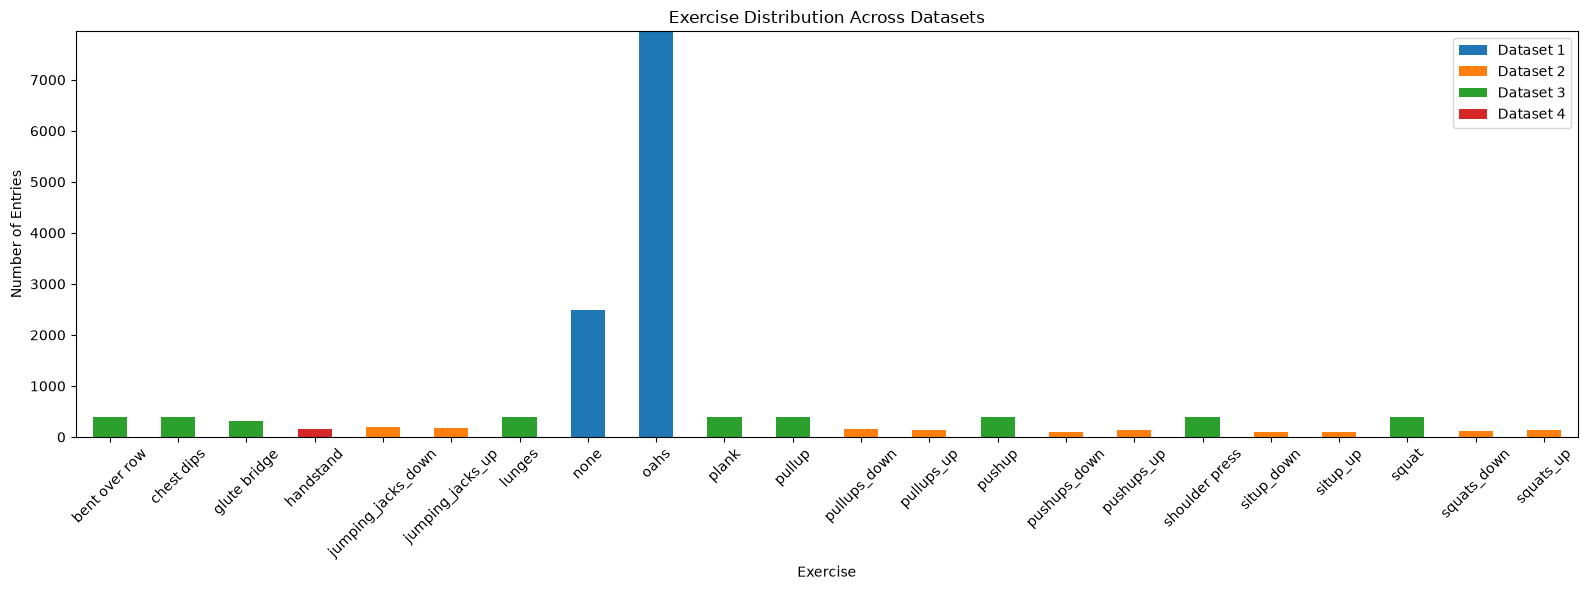

In [4]:
counts = pd.DataFrame({
    "Dataset 1": d1_exercises.value_counts(),
    "Dataset 2": d2_exercises.value_counts(),
    "Dataset 3": d3_exercises.value_counts(),
    "Dataset 4": d4_exercises.value_counts(),
}).fillna(0)

ax = counts.plot(kind="bar", stacked=True, figsize=(16, 6))

ax.set_title("Exercise Distribution Across Datasets")
ax.set_xlabel("Exercise")
ax.set_ylabel("Number of Entries")
ax.tick_params(axis="x", labelrotation=45)

plt.tight_layout()
plt.show()

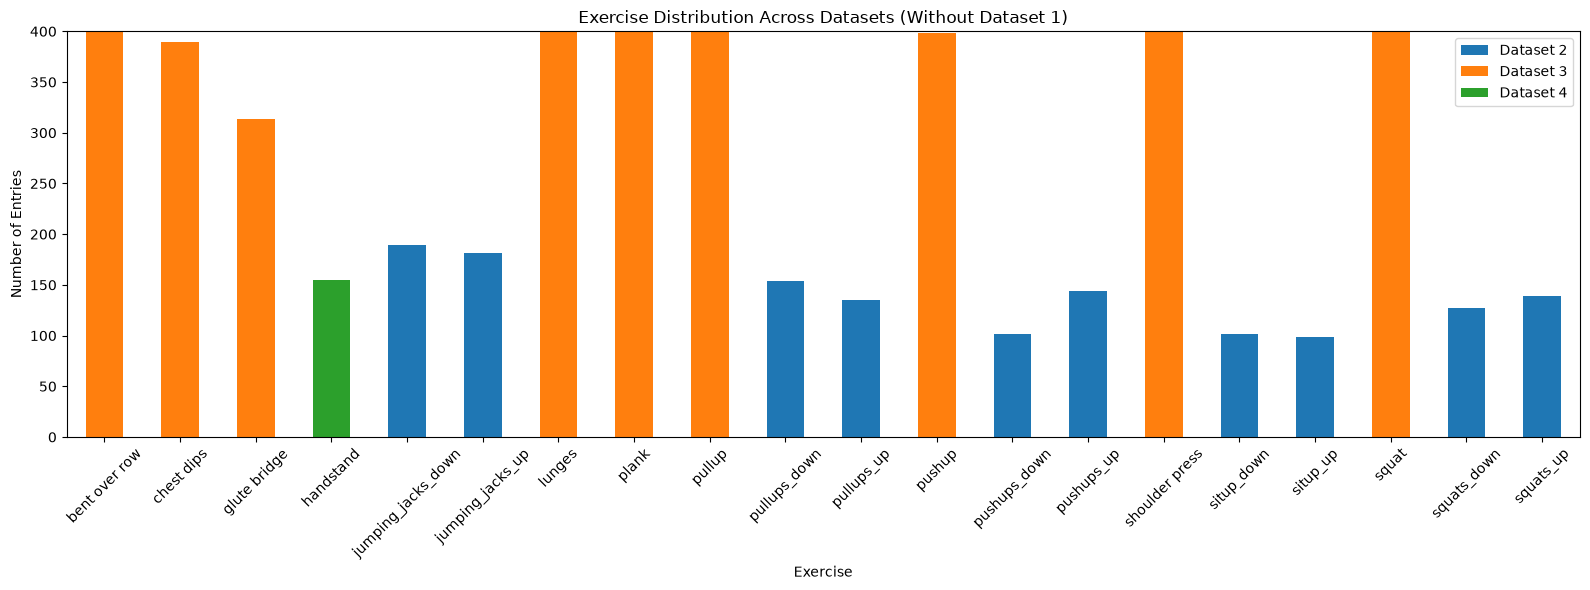

In [5]:
countsNo1 = pd.DataFrame({
    "Dataset 2": d2_exercises.value_counts(),
    "Dataset 3": d3_exercises.value_counts(),
    "Dataset 4": d4_exercises.value_counts(),
}).fillna(0)

ax = countsNo1.plot(kind="bar", stacked=True, figsize=(16, 6))

ax.set_title("Exercise Distribution Across Datasets (Without Dataset 1)")
ax.set_xlabel("Exercise")
ax.set_ylabel("Number of Entries")
ax.tick_params(axis="x", labelrotation=45)

plt.tight_layout()
plt.show()

## Processed data (4 selected exercises)

Run `preprocess.ipynb` first. It creates `processed_data/poses.csv`.

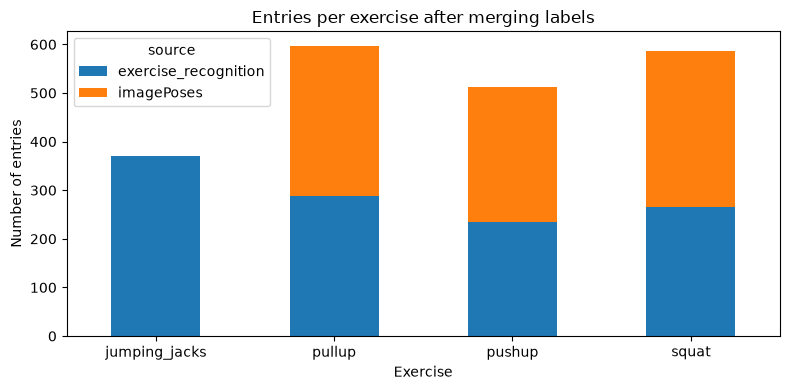

In [6]:
import numpy as np

poses = pd.read_csv("../processed_data/poses.csv")
LANDMARKS = [c[2:] for c in poses.columns if c.startswith("x_")]
XY_COLUMNS = [c for c in poses.columns if c[:2] in ("x_", "y_")]
EXERCISES = sorted(poses["label"].unique())
SOURCES = sorted(poses["source"].unique())

ax = pd.crosstab(poses["label"], poses["source"]).plot(kind="bar", stacked=True, figsize=(8, 4))
ax.set_title("Entries per exercise after merging labels")
ax.set_xlabel("Exercise")
ax.set_ylabel("Number of entries")
ax.tick_params(axis="x", labelrotation=0)
plt.tight_layout()
plt.show()

Median pose per exercise, drawn as a stick figure, one color per source dataset. If normalization unified the datasets, the two skeletons for the same exercise should roughly overlap. Some blur is expected because people face different directions.

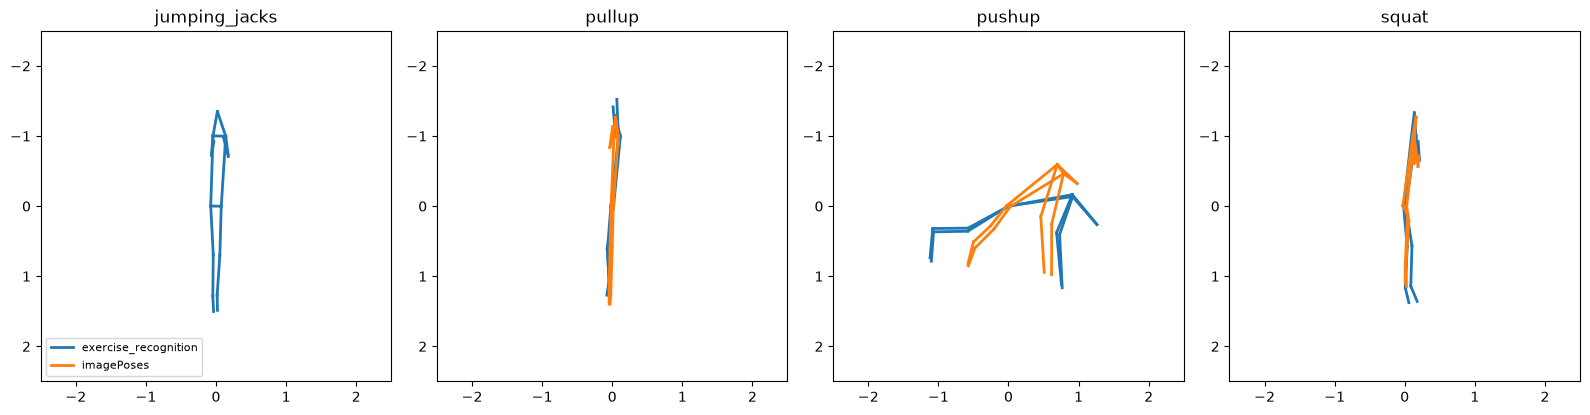

In [7]:
CONNECTIONS = [
    ("left_shoulder", "right_shoulder"), ("left_hip", "right_hip"),
    ("left_shoulder", "left_hip"), ("right_shoulder", "right_hip"),
    ("left_shoulder", "left_elbow"), ("left_elbow", "left_wrist"),
    ("right_shoulder", "right_elbow"), ("right_elbow", "right_wrist"),
    ("left_hip", "left_knee"), ("left_knee", "left_ankle"),
    ("right_hip", "right_knee"), ("right_knee", "right_ankle"),
    ("left_ankle", "left_foot_index"), ("right_ankle", "right_foot_index"),
    ("left_shoulder", "nose"), ("right_shoulder", "nose"),
]


def draw_skeleton(ax, pose, color, label=None):
    for i, (a, b) in enumerate(CONNECTIONS):
        ax.plot([pose[f"x_{a}"], pose[f"x_{b}"]], [pose[f"y_{a}"], pose[f"y_{b}"]],
                color=color, linewidth=2, label=label if i == 0 else None)


fig, axes = plt.subplots(1, len(EXERCISES), figsize=(4 * len(EXERCISES), 4.5))
for ax, exercise in zip(axes, EXERCISES):
    for source, color in zip(SOURCES, ["tab:blue", "tab:orange"]):
        subset = poses[(poses["label"] == exercise) & (poses["source"] == source)]
        draw_skeleton(ax, subset[XY_COLUMNS].median(), color, source)
    ax.set_title(exercise)
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(2.5, -2.5)
    ax.set_aspect("equal")
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

Joint angles per exercise. These are meaningful, scale-independent summaries of a pose and could also be used as model features. Each angle is averaged over the left and right side.

- **Elbow / knee / hip angle**: 180° = straight, smaller = more bent
- **Torso angle**: angle between the hip-to-shoulder line and straight up (0° = upright, 90° = horizontal, 180° = upside down)

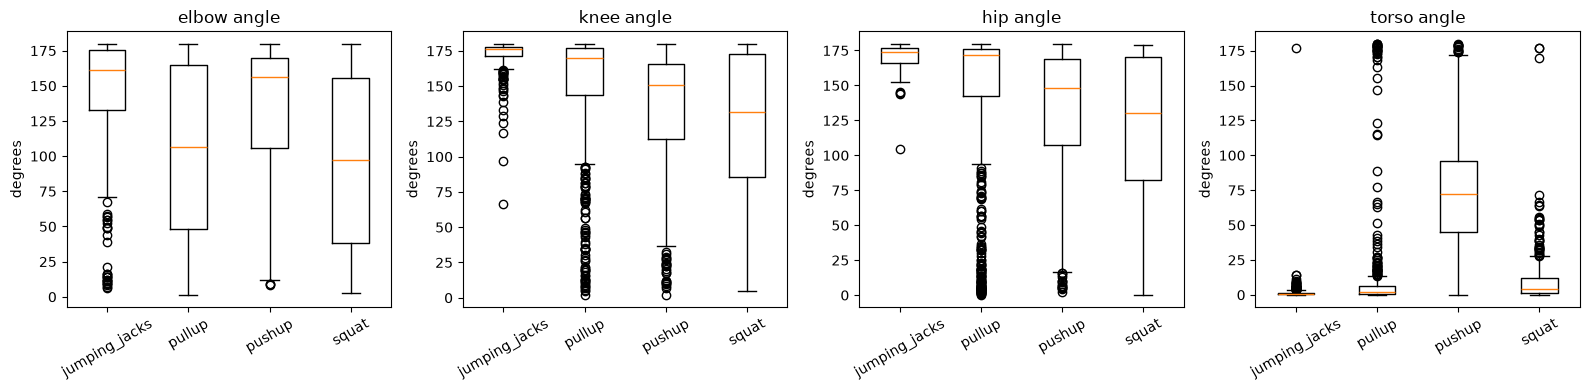

,elbow,knee,hip,torso
label,,,,
jumping_jacks,161.1,176.1,174.3,0.9
pullup,106.2,169.8,171.9,2.2
pushup,156.5,150.6,148.4,72.2
squat,97.4,132.0,130.3,4.1


In [8]:
def joint_angle(df, a, b, c):
    """Angle at point b (degrees) formed by a-b-c."""
    v1 = np.stack([df[f"x_{a}"] - df[f"x_{b}"], df[f"y_{a}"] - df[f"y_{b}"]], axis=1)
    v2 = np.stack([df[f"x_{c}"] - df[f"x_{b}"], df[f"y_{c}"] - df[f"y_{b}"]], axis=1)
    cos = (v1 * v2).sum(axis=1) / (np.linalg.norm(v1, axis=1) * np.linalg.norm(v2, axis=1))
    return np.degrees(np.arccos(np.clip(cos, -1, 1)))


def both_sides(df, a, b, c):
    return (joint_angle(df, f"left_{a}", f"left_{b}", f"left_{c}")
            + joint_angle(df, f"right_{a}", f"right_{b}", f"right_{c}")) / 2


shoulder_x = (poses["x_left_shoulder"] + poses["x_right_shoulder"]) / 2
shoulder_y = (poses["y_left_shoulder"] + poses["y_right_shoulder"]) / 2
angles = pd.DataFrame({
    "label": poses["label"],
    "elbow": both_sides(poses, "shoulder", "elbow", "wrist"),
    "knee": both_sides(poses, "hip", "knee", "ankle"),
    "hip": both_sides(poses, "shoulder", "hip", "knee"),
    "torso": np.degrees(np.arccos(np.clip(-shoulder_y / np.hypot(shoulder_x, shoulder_y), -1, 1))),
})

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ["elbow", "knee", "hip", "torso"]):
    ax.boxplot([angles.loc[angles["label"] == e, col] for e in EXERCISES], tick_labels=EXERCISES)
    ax.set_title(f"{col} angle")
    ax.set_ylabel("degrees")
    ax.tick_params(axis="x", labelrotation=30)
plt.tight_layout()
plt.show()

angles.groupby("label").median().round(1)

PCA projection of all normalized poses to 2D. Left: colored by exercise. Right: colored by source dataset. We want points to group by exercise, not by dataset. Grouping by dataset would mean the model could learn dataset differences instead of exercises.

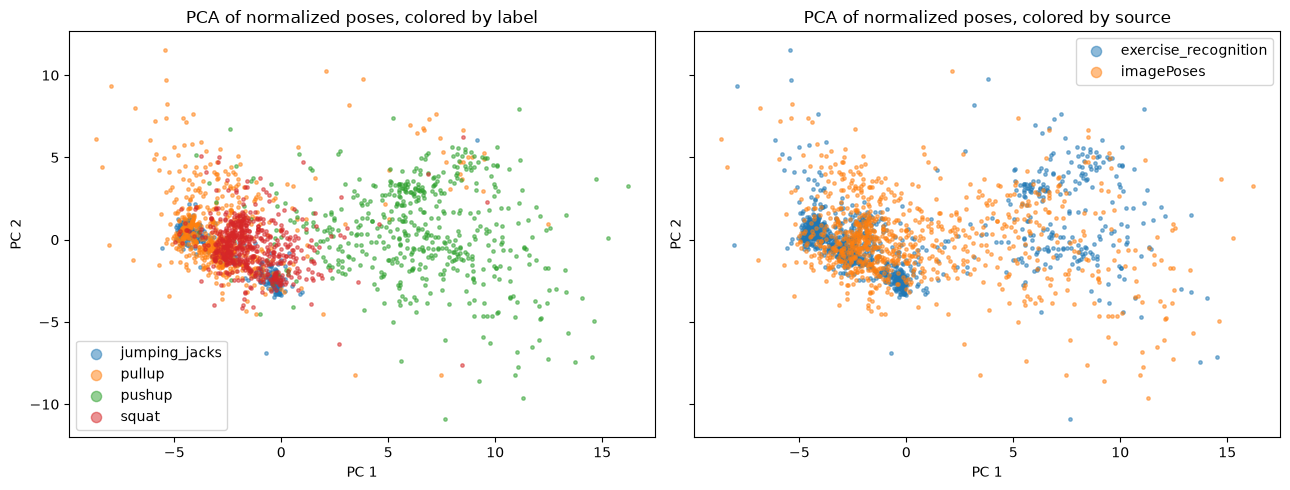

In [9]:
X = poses[XY_COLUMNS].to_numpy()
X = X - X.mean(axis=0)
_, _, components = np.linalg.svd(X, full_matrices=False)
projected = X @ components[:2].T

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, column, names in [(axes[0], "label", EXERCISES), (axes[1], "source", SOURCES)]:
    for name in names:
        mask = (poses[column] == name).to_numpy()
        ax.scatter(projected[mask, 0], projected[mask, 1], s=6, alpha=0.5, label=name)
    ax.set_title(f"PCA of normalized poses, colored by {column}")
    ax.set_xlabel("PC 1")
    ax.set_ylabel("PC 2")
    ax.legend(markerscale=3)
plt.tight_layout()
plt.show()